# 27 · Set 9: the 0.5B learns where each question should go; ensembles, calibrated escalation, Sure / Unsure (A100)

Needs notebook 26 to be finished (it trains the 0.5B retriever and makes most of the test answers this notebook reuses).

**What the 0.5B learns.** After its shortlist it writes two more lines:

```
Selected references: [3] [11]
Shortlist with: 0.5B | 0.6B | 0.8B | 3B
Answer with: Llama 8B | Qwen 32B | Qwen 32B, likely wrong
```

| | |
|---|---|
| Labelling questions | About 3,300 hard HotpotQA training questions that **no retriever was trained on** (not among notebook 23a's 12,000 + 300) |
| Labels | *Shortlist with* = the cheapest fine-tuned retriever whose shortlist holds both gold passages. *Answer with* = Llama if Llama is right on the 0.5B shortlist, else Qwen if Qwen is, else "Qwen 32B, likely wrong" |
| Teaching | About 2,300 of them: a short LoRA on the 0.5B from notebook 26 (2 passes) |
| Calibration | The other 1,000: the scores of both stages and the threshold pair chosen there |
| Test | The 400 test questions, used once |

**Both stages work the same way:**

| Step | Retrieval | Answer |
|---|---|---|
| 1. Learned start | The retriever the 0.5B named | The answerer the 0.5B named |
| 2. Ensemble | With the 0.5B's own shortlist: agree → keep; majority; else union | Votes: Llama start → Llama, + Qwen, + 4 Qwen samples; Qwen start → Qwen, + 2 samples, + 2 samples and Llama. Majority by agreement |
| 3. Score | Calibrated chance that both gold passages are in the shortlist | Calibrated chance that the answer is right |
| 4. Below the threshold | Add the next larger retriever, score again | Next step of votes, score again |
| Flag | Retrieval **Sure / Unsure** | Answer **Sure / Unsure** (also when Qwen 32B is unsure) |

Thresholds: **0.90 / 0.90 stated beforehand** (so "Sure" should mean about 90% right), and the pair chosen on the calibration
questions. Compared with: the cheap fixed setup, 3B → Qwen 32B (84.2%), the same cascade without the learned start, the learned
start without ensembles, and everything always run. Output includes a per-question table: route, retrievers run, scores, flags,
answer, compute.

**My estimate:** labelling questions built 10–15 min; retrieval about 20 min; Llama and Qwen answers on the labelling questions
about 80–100 min; teaching the route about 20–30 min; calibration and test answers and samples about 60–80 min; analysis a
few minutes. **About 4–4.5 hours.** Resumable: if the session stops, run the notebook again.

Output: `runs/Set_3__self-learnt-retrieval/<timestamp>_<GPU>_route05/results/` (`summary.md`, `set9_learned_route.xlsx`, `charts/accuracy_vs_compute.png`).

**Runtime → Change runtime type → A100 GPU.**

In [10]:
# ==== settings ====
PROJECT_DIR = "/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching"
EXPERIMENT  = "Set_3__self-learnt-retrieval"
EXP_SET5    = "Set_2__question-reading-routers"
OLD_SWEEP_EXPERIMENT = "Set_1__3-modality-size"
FRESH_DATA  = f"{PROJECT_DIR}/data/hotpotqa_q/fresh200_c20_s43"
N_CALIB = 1000                        # labelling questions kept for calibration (the rest teach the route lines)
ROUTE_EPOCHS = 2
TARGET = 0.90                         # threshold stated beforehand: a 'Sure' answer should be right about 90% of the time
TIME_LIMIT_MIN = 600                  # stops cleanly at this limit; run the notebook again to continue
NEW_RUN = False                       # False = continue the latest run of this notebook
DRY_RUN = False                       # True = tiny model and fake answers on CPU: tests the whole notebook in a few minutes

EXPECTED_CODE = {
 "ssw.py": "c9fbdc7f6b91c58b607021b8be8c03ae2ff67dc1024fd2e24fffeb18e239ed98",
 "sweep.py": "9382292c6fe396cf79c73b212aaf6c2d677cae7f9311c3a5304f0578b52e6bb6",
 "routers.py": "8a293df1c8955716950f535cf9a3ced24439e00250173da1a3df110c0ed87304",
 "hidden.py": "574e6c1390e47c6de833a0c10b32c24eed0dee73a35eabc17f58842835e7f105",
 "final.py": "f18a6fba3d1bdd1f6700f6dc535f10ec0c41dbf5192b7b39ad097f8a1b88be53",
 "retriever_check.py": "fde08c549ecbd6bfc5527a42c731aa51dcff687a64818d68cf9cb30090e017e3",
 "ensemble.py": "5c5e87175d2484d806fda913a9555f71378a6031f050c37e89c20305942b76fc",
 "experts.py": "17ed39957e54853d178b47fa73ba328b50f0589b129ccb191a2efb0a2dea466b",
 "retft.py": "4a0d27d24459ba179c60dcce39a85285ae422dfa9e8d7cbc160e79a0a9932879",
 "casc8.py": "ba0d23a1aed58e9da5426406c0c953ae04b97c46cbaa820fa53328ea3e4c0bdd",
 "route9.py": "774600dad0bebf98f4957ab3131e23936973dc6cb117f0912cb4f01a5f96a83e"
}

In [11]:
import subprocess, sys, os, json, shutil, time
gpu = subprocess.run("nvidia-smi --query-gpu=name,memory.total,compute_cap --format=csv,noheader 2>/dev/null",
                     shell=True, capture_output=True, text=True).stdout.strip()
print("GPU:", gpu or "none")
if not DRY_RUN:
    assert gpu, "No GPU: Runtime -> Change runtime type -> A100 GPU (or set DRY_RUN = True)."
    if "T4" in gpu:
        raise SystemExit("This runtime has a T4, which cannot run this: the 7B model alone (15 GB) does not fit in its memory.\n"
                         "Runtime -> Change runtime type -> A100 GPU (or G4 / L4) -> Save, then run all cells again.")
    if "A100" not in gpu and "G4" not in gpu and "RTX PRO 6000" not in gpu:
        print("Note: planned for an A100 or G4; this GPU works but timings will differ.")
GPU_TAG = "cpu" if not gpu else gpu.split(",")[0].replace("NVIDIA", "").replace("Tesla", "").strip().split()[0].split("-")[0]
T_START = time.time()

GPU: NVIDIA A100-SXM4-40GB, 40960 MiB, 8.0


In [12]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Check that Drive is serving the current code; find notebook 26's run

In [13]:
import glob, hashlib
from datetime import datetime
from zoneinfo import ZoneInfo
def sha(p):
    return hashlib.sha256(open(p, "rb").read()).hexdigest()
CODE_DIR = "/content/set9code"
os.makedirs(CODE_DIR, exist_ok=True)
stale = []
for f, want in EXPECTED_CODE.items():
    shutil.copy(f"{PROJECT_DIR}/code/{f}", f"{CODE_DIR}/{f}")
    if sha(f"{CODE_DIR}/{f}") != want:
        stale.append(f)
assert not stale, (f"Drive is serving a different version of {stale} than this notebook was made for. Wait two minutes, then "
                   "Runtime -> Disconnect and delete runtime, and run again.")
sweeps = [d for d in sorted(glob.glob(f"{PROJECT_DIR}/runs/{OLD_SWEEP_EXPERIMENT}/*")) if "_dryrun" not in d and os.path.exists(f"{d}/results/per_question.jsonl")
          and os.path.exists(f"{d}/sweep_status.json") and json.load(open(f"{d}/sweep_status.json")).get("complete")]
fresh = [d for d in sorted(glob.glob(f"{PROJECT_DIR}/runs/{EXP_SET5}/*_final")) if os.path.exists(f"{d}/step/retrieval_q7_c1_p3.jsonl")]
casc = [d for d in sorted(glob.glob(f"{PROJECT_DIR}/runs/{EXPERIMENT}/*_casc05" + ("_dryrun" if DRY_RUN else "")))
        if os.path.exists(f"{d}/results/summary.md") and os.path.exists(f"{d}/adapter/train_state.json")]
set7 = [d for d in sorted(glob.glob(f"{PROJECT_DIR}/runs/{EXPERIMENT}/*_ft*")) if "_dryrun" not in d and os.path.exists(f"{d}/step/answers_q32.jsonl")]
assert sweeps and fresh, "Needs the finished runs of notebooks 11 and 17."
assert casc, "Needs the finished run of notebook 26 (with results/summary.md)."
OLD_SWEEP, FRESH_RUN, CASC_RUN = sweeps[-1], fresh[-1], casc[-1]
OLD_DATA = json.load(open(f"{OLD_SWEEP}/config.json"))["data_dir"]
CASC_CFG = json.load(open(f"{CASC_RUN}/config.json"))
ADAPTERS = CASC_CFG["adapters"]                      # r05 (notebook 26), r06 (25a), r08 (25b), r3 (23a)
LABEL_DIR = f"{PROJECT_DIR}/data/hotpotqa_train/label_rest_c20_hard_s7" + ("_dryrun" if DRY_RUN else "")
SESSION = datetime.now(ZoneInfo("Asia/Singapore")).strftime("%Y%m%d-%H%M%S")
tag = "_route05_dryrun" if DRY_RUN else "_route05"
prev = sorted(glob.glob(f"{PROJECT_DIR}/runs/{EXPERIMENT}/*{tag}"))
RUN_DIR = prev[-1] if (prev and not NEW_RUN) else f"{PROJECT_DIR}/runs/{EXPERIMENT}/{SESSION}_{GPU_TAG}{tag}"
SESSION_DIR = f"{RUN_DIR}/sessions/{SESSION}"
for d in (f"{RUN_DIR}/code", f"{RUN_DIR}/logs", f"{RUN_DIR}/step", SESSION_DIR):
    os.makedirs(d, exist_ok=True)
for f in EXPECTED_CODE:
    shutil.copy(f"{CODE_DIR}/{f}", f"{RUN_DIR}/code/{f}")
TIMES = {}
print("Code files: current.")
print("Notebook 26 run: ", CASC_RUN)
print("Adapters:        ", json.dumps(ADAPTERS, indent=1))
print("Run folder:      ", RUN_DIR)

Code files: current.
Notebook 26 run:  /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_3__self-learnt-retrieval/20261013-133655_A100_casc05
Adapters:         {
 "r05": "/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_3__self-learnt-retrieval/20261013-133655_A100_casc05/adapter",
 "r06": "/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_3__self-learnt-retrieval/20261013-091250_A100_ftq06_12k/adapter",
 "r08": "/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_3__self-learnt-retrieval/20261013-091335_A100_ftq08_12k/adapter",
 "r3": "/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_3__self-learnt-retrieval/20261011-134625_A100_ft3_12k/adapter"
}
Run folder:       /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_3__self-learnt-retrieval/20261013-162007_A100_route05


In [14]:
MODELS = {   # key: model, folder under models/, parameters (for compute), nominal size (for the AgentTTS budget formula)
    "q3":  {"id": "Qwen/Qwen2.5-3B-Instruct",        "dir": "Qwen2.5-3B-Instruct",        "params": 3.09e9,  "nominal": 3e9},
    "q7":  {"id": "Qwen/Qwen2.5-7B-Instruct",        "dir": "Qwen2.5-7B-Instruct",        "params": 7.62e9,  "nominal": 7e9},
    "q32": {"id": "Qwen/Qwen2.5-32B-Instruct-AWQ",   "dir": "Qwen2.5-32B-Instruct-AWQ",   "params": 32.76e9, "nominal": 32e9},
    "l3":  {"id": "meta-llama/Llama-3.2-3B-Instruct", "dir": "Llama-3.2-3B-Instruct",     "params": 3.21e9,  "nominal": 3e9},
    "l8":  {"id": "meta-llama/Llama-3.1-8B-Instruct", "dir": "Llama-3.1-8B-Instruct",     "params": 8.03e9,  "nominal": 8e9},
}
LOCAL = "/content/models"
for m in MODELS.values():
    m["path"] = f"{LOCAL}/{m['dir']}"

MODELS = {k: v for k, v in MODELS.items() if k in ("q3", "q7", "l8", "q32")}
BASES = {"r05": ("Qwen2.5-0.5B-Instruct", 0.49e9), "r06": ("Qwen3-0.6B", 0.6e9), "r08": ("Qwen3.5-0.8B", 0.8e9), "r3": ("Qwen2.5-3B-Instruct", 3.09e9)}
FTKEY = {r: f"{r}ft" for r in BASES}
for r, (bdir, params) in BASES.items():
    MODELS[FTKEY[r]] = {"id": f"{bdir} + LoRA ({ADAPTERS[r]})", "dir": FTKEY[r] + "_merged", "params": params, "nominal": params, "path": f"{LOCAL}/{FTKEY[r]}_merged"}
MODELS["r05route"] = {"id": "Qwen2.5 0.5B retriever + route LoRA trained in this run", "dir": "r05route_merged", "params": 0.49e9, "nominal": 0.49e9,
                      "path": f"{LOCAL}/r05route_merged"}
json.dump(MODELS, open(f"{RUN_DIR}/models.json", "w"), indent=1)
json.dump({"experiment": EXPERIMENT, "set": "9 learned route + ensembles + calibrated escalation + Sure/Unsure", "casc_run": CASC_RUN, "adapters": ADAPTERS,
           "old_sweep": OLD_SWEEP, "fresh_run": FRESH_RUN, "old_data": OLD_DATA, "fresh_data": FRESH_DATA, "label_dir": LABEL_DIR, "n_calib": N_CALIB,
           "route_epochs": ROUTE_EPOCHS, "target": TARGET, "gpu": gpu, "dry_run": DRY_RUN, "code": EXPECTED_CODE, "started": SESSION},
          open(f"{RUN_DIR}/config.json", "w"), indent=1)

def minutes_left():
    return max(0.0, TIME_LIMIT_MIN - (time.time() - T_START) / 60)

def run_stage(args, log_name, script="route9.py"):
    cmd = [sys.executable, "-u", f"{CODE_DIR}/{script}"] + [str(a) for a in args]
    t0 = time.time()
    with open(f"{RUN_DIR}/logs/{log_name}", "a") as log, open(f"{SESSION_DIR}/{log_name}", "a") as slog:
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
        for line in p.stdout:
            log.write(line); slog.write(line)
            if not any(k in line for k in ("it/s]", "s/it]", "Loading checkpoint", "INFO ", "(EngineCore", "WARNING ", "Warning", "warn", "Loading weights", "Writing model")):
                print(line, end="")
        p.wait()
    TIMES[log_name.replace(".log", "")] = TIMES.get(log_name.replace(".log", ""), 0) + round(time.time() - t0)
    json.dump(TIMES, open(f"{SESSION_DIR}/stage_times.json", "w"), indent=1)
    print(f"--- {log_name}: exit {p.returncode}, {time.time() - t0:.0f}s, {minutes_left():.0f} min left of the limit")
    assert p.returncode == 0, f"stage failed - see {RUN_DIR}/logs/{log_name}"

BACKEND = "mock" if DRY_RUN else "vllm"
COMMON = ["--old_sweep", OLD_SWEEP, "--old_data", OLD_DATA, "--fresh_run", FRESH_RUN, "--fresh_data", FRESH_DATA, "--run_dir", RUN_DIR,
          "--models_json", f"{RUN_DIR}/models.json", "--label_dir", LABEL_DIR]
STEP = f"{RUN_DIR}/step"
ROUTE_ADAPTER = f"{RUN_DIR}/route_adapter"
def route_trained():
    s = f"{ROUTE_ADAPTER}/train_state.json"
    return os.path.exists(s) and "chosen" in json.load(open(s))

### 1. Copy the answerers to local disk (background), install peft

In [15]:
import importlib.util, threading
COPY = {"err": None, "done": set(), "seconds": {}}
def _copy_all(keys):
    try:
        for key in keys:
            m = MODELS[key]
            src = f"{PROJECT_DIR}/models/{m['dir']}"
            if not os.path.exists(f"{m['path']}/config.json"):
                assert os.path.exists(f"{src}/config.json"), f"{src} missing."
                t = time.time()
                shutil.rmtree(m["path"] + ".part", ignore_errors=True)
                shutil.copytree(src, m["path"] + ".part")
                os.rename(m["path"] + ".part", m["path"])
                COPY["seconds"][key] = round(time.time() - t)
            COPY["done"].add(key)
    except Exception as e:
        COPY["err"] = e

def wait_local(key):
    if DRY_RUN:
        return
    while key not in COPY["done"]:
        if COPY["err"]:
            raise COPY["err"]
        time.sleep(5)
    TIMES[f"copy_{key}"] = COPY["seconds"].get(key, 0)

if not DRY_RUN:
    os.makedirs(LOCAL, exist_ok=True)
    threading.Thread(target=_copy_all, args=(["l8", "q32"],), daemon=True).start()
if importlib.util.find_spec("peft") is None:
    print("installing peft ...")
    !pip install -q peft
if not DRY_RUN and importlib.util.find_spec("fla") is None:
    print("installing flash-linear-attention (for Qwen3.5 0.8B) ...")
    !pip install -q flash-linear-attention

installing flash-linear-attention (for Qwen3.5 0.8B) ...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.6/45.6 kB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.3/45.3 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 399.6/399.6 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 819.2/819.2 kB 38.0 MB/s eta 0:00:00


### 2. The labelling questions (HotpotQA training questions no retriever was trained on; first time only)

In [16]:
if not os.path.exists(f"{LABEL_DIR}/calib.json"):
    if DRY_RUN:
        run_stage(["build_label", "--hotpot_train", f"{PROJECT_DIR}/AgentTTS/data/HotpotQA/hotpotqa-dev.json", "--skip_first", 7000, "--n_max", 150,
                   "--n_calib", 50] + COMMON, "build_label.log")
    else:
        run_stage(["build_label", "--n_calib", N_CALIB] + COMMON, "build_label.log")
cfg = json.load(open(f"{LABEL_DIR}/data_config.json"))
print(f"route-teaching questions: {cfg['route_train']}, calibration questions: {cfg['calib']}")

[08:20:16] downloading http://curtis.ml.cmu.edu/datasets/hotpot/hotpot_train_v1.1.json (about 570 MB) ...
[08:22:29] official download failed (URLError: <urlopen error [Errno 110] Connection timed out>); trying the Hugging Face copy

Generating train split: 100%|██████████| 90447/90447 [00:02<00:00, 39947.01 examples/s]

Generating validation split: 100%|██████████| 7405/7405 [00:00<00:00, 42566.80 examples/s]
[08:23:19] 15661 hard training questions; 3361 not used for training or validation; BM25 over 129752 paragraphs ...
[08:23:46] labelling questions: 2361 for teaching the route lines, 1000 for calibration -> /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/data/hotpotqa_train/label_rest_c20_hard_s7
--- build_label.log: exit 0, 212s, 596 min left of the limit
route-teaching questions: 2361, calibration questions: 1000


### 3. Merge the four fine-tuned retrievers

In [17]:
for r, (bdir, params) in BASES.items():
    run_stage(["merge", "--adapter_dir", ADAPTERS[r], "--merged_dir", MODELS[FTKEY[r]]["path"], "--base", f"{PROJECT_DIR}/models/{bdir}"]
              + (["--backend", "tiny"] if DRY_RUN else []), "merge.log", script="retft.py")


[08:24:27] loaded /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/models/Qwen2.5-0.5B-Instruct as Qwen2ForCausalLM (AutoModelForCausalLM)

[08:24:42] merged /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_3__self-learnt-retrieval/20261013-133655_A100_casc05/adapter/ckpt_step2989 -> /content/models/r05ft_merged
--- merge.log: exit 0, 61s, 595 min left of the limit

[08:25:11] loaded /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/models/Qwen3-0.6B as Qwen3ForCausalLM (AutoModelForCausalLM)

[08:25:27] merged /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_3__self-learnt-retrieval/20261013-091250_A100_ftq06_12k/adapter/ckpt_step1494 -> /content/models/r06ft_merged
--- merge.log: exit 0, 40s, 595 min left of the limit

[08:25:56] loaded /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/models/Qwen3.5-0.8B as Qwen3_5ForCausalLM (AutoModelForCausalLM)

[08:26:18] me

### 4. Retrieval: all four retrievers on the labelling questions; 0.6B, 0.8B and 3B on the test questions (vLLM)

In [18]:
if not DRY_RUN and importlib.util.find_spec("vllm") is None:
    t = time.time()
    !pip install -q vllm
    !pip uninstall -y -q torchaudio   # Colab's torchaudio is built for another CUDA version and breaks imports
    chk = subprocess.run([sys.executable, "-c", "from vllm import LLM; import vllm, torch; print('vLLM', vllm.__version__, '| torch', torch.__version__)"],
                         capture_output=True, text=True)
    print(chk.stdout or chk.stderr[-2000:])
    assert chk.returncode == 0, "vLLM does not import - Runtime -> Disconnect and delete runtime, then run again."
    TIMES["install_vllm"] = round(time.time() - t)
run_stage(["retrieve", "--set", "label", "--backend", BACKEND, "--retrievers"] + [f"{r}:{FTKEY[r]}" for r in BASES] + COMMON, "retrieve.log")
run_stage(["retrieve", "--set", "test", "--backend", BACKEND, "--retrievers"] + [f"{r}:{FTKEY[r]}" for r in ("r06", "r08", "r3")] + COMMON, "retrieve.log")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 320.6/320.6 MB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 60.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.7/211.7 kB 21.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.7/33.7 MB 38.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 426.0/426.0 kB 35.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.0/111.0 kB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.4/45.4 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 49.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 782.6/782.6 kB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 46.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.2/43.2 MB 24.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 729.6

### 5. Labels: Llama 8B and Qwen 32B answer the route-teaching questions on the 0.5B shortlists

In [19]:
run_stage(["reach", "--sets", "route_train"] + COMMON, "reach.log")
for key in ("l8", "q32"):
    wait_local(key)
run_stage(["answer", "--backend", BACKEND, "--shortlists", f"{STEP}/route_train_shortlists.jsonl"] + COMMON, "answer_labels.log")
run_stage(["route_data"] + COMMON, "route_data.log")

[08:57:04] route_train: 2361 shortlists
--- reach.log: exit 0, 1s, 563 min left of the limit
[08:57:05] l8: 2361 answers to generate











[08:59:34]   l8: 256/2361
[08:59:52]   l8: 512/2361
[09:00:11]   l8: 768/2361
[09:00:28]   l8: 1024/2361
[09:00:46]   l8: 1280/2361
[09:01:04]   l8: 1536/2361
[09:01:22]   l8: 1792/2361
[09:01:41]   l8: 2048/2361
[09:01:59]   l8: 2304/2361
[09:02:09]   l8: 2361/2361
[09:02:11] q32: 2361 answers to generate












[09:05:44]   q32: 256/2361
[09:06:39]   q32: 512/2361
[09:07:31]   q32: 768/2361
[09:08:22]   q32: 1024/2361
[09:09:15]   q32: 1280/2361
[09:10:07]   q32: 1536/2361
[09:11:00]   q32: 1792/2361
[09:11:52]   q32: 2048/2361
[09:12:44]   q32: 2304/2361
[09:12:56]   q32: 2361/2361
--- answer_labels.log: exit 0, 957s, 547 min left of the limit
[09:13:03] route training examples: 2211 (+150 validation). Labels:
[09:13:03]    0.5B | Llama 8B                  1590 (67.3%)
[09:13:03]    0.5B | Qwen 32B, likely wrong     201 (8.5%)
[09:13:03

### 6. Teach the 0.5B the two route lines (LoRA on notebook 26's merged 0.5B; resumable)

In [20]:
if not route_trained() or not os.path.exists(f"{MODELS['r05route']['path']}/config.json"):
    run_stage(["train_route", "--out_dir", ROUTE_ADAPTER, "--merged_dir", MODELS["r05route"]["path"], "--base", MODELS[FTKEY["r05"]]["path"],
               "--epochs", ROUTE_EPOCHS, "--backend", "tiny" if DRY_RUN else "hf", "--time_limit_min", max(5.0, minutes_left() - 100)] + COMMON, "train_route.log")
ROUTE_DONE = route_trained()
print("Route lines taught." if ROUTE_DONE else "NOT COMPLETE YET - run this notebook again to continue.")


[09:13:14] loaded /content/models/r05ft_merged as Qwen2ForCausalLM (AutoModelForCausalLM)
[09:13:34] training examples: 2201 (dropped 10 longer than 4096 tokens); mean length 2680 tokens
[09:13:35] LoRA r=16: 8.8M trainable parameters; 550 optimizer steps (8 questions each, micro-batches of 4); validation checkpoints at steps [550]; resume point every 62 steps
[09:14:31]   step 25/550 | loss 1.785 | 0.9 min this session
[09:15:23]   step 50/550 | loss 0.089 | 1.8 min this session
[09:16:17]   step 75/550 | loss 0.077 | 0.5 min this session
[09:17:09]   step 100/550 | loss 0.083 | 1.3 min this session
[09:18:02]   step 125/550 | loss 0.070 | 0.0 min this session
[09:18:55]   step 150/550 | loss 0.079 | 0.9 min this session
[09:19:48]   step 175/550 | loss 0.064 | 1.8 min this session
[09:20:42]   step 200/550 | loss 0.057 | 0.5 min this session
[09:21:35]   step 225/550 | loss 0.074 | 1.4 min this session
[09:22:28]   step 250/550 | loss 0.068 | 0.1 min this session
[09:23:20]   step 2

### 7. The route model reads the calibration and test questions (its shortlist, its choices, its probabilities)

In [21]:
if ROUTE_DONE:
    for st in ("calib", "test"):
        run_stage(["route", "--set", st, "--backend", "mock" if DRY_RUN else "hf"] + COMMON, "route.log")

[09:37:13] route read-out on calib: 1000 questions to do

[09:37:23] loaded /content/models/r05route_merged as Qwen2ForCausalLM (AutoModelForCausalLM)
[W1013 09:37:45.193458960 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 7566524416 bytes (free: 7381385216, total: 42405855232).
[W1013 09:38:07.560792949 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 8264876032 bytes (free: 3291938816, total: 42405855232).
[09:38:29]   calib: 50/1000
[09:39:32]   calib: 100/1000
[W1013 09:39:40.781360020 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 8594128896 bytes (free: 8492875776, total: 42405855232).
[09:40:37]   calib: 150/1000
[W1013 09:40:52.955078665 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 9175040000 bytes (free: 5361827840, total: 42405855232).
[W1013 09:41:06.5867096

### 8. Answers and samples on every shortlist either ladder can reach (most test answers reused from notebook 26)

In [22]:
ALL_DONE = False
if ROUTE_DONE:
    run_stage(["reach", "--sets", "calib", "test"] + COMMON, "reach.log")
    REACH = [f"{STEP}/calib_reach.jsonl", f"{STEP}/test_reach.jsonl"]
    run_stage(["answer", "--backend", BACKEND, "--require_logprob", "--shortlists"] + REACH + ["--cache_dirs", CASC_RUN] + COMMON, "answer.log")
    run_stage(["answer", "--backend", BACKEND, "--models", "q32", "--shortlists", f"{STEP}/test_ref_shortlists.jsonl", "--cache_dirs", CASC_RUN] + set7 + COMMON,
              "answer_ref.log")
    run_stage(["sample", "--backend", BACKEND, "--n", 4, "--shortlists"] + REACH + ["--cache_dirs", CASC_RUN] + COMMON, "sample.log")
    ALL_DONE = True

[10:07:43] calib: 1626 reachable shortlists (1.63 per question)
[10:07:44] test: 621 reachable shortlists (1.55 per question)
--- reach.log: exit 0, 2s, 492 min left of the limit
[10:07:46] l8: reused 567 answers from ['/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_3__self-learnt-retrieval/20261013-133655_A100_casc05']
[10:07:46] l8: 1680 answers to generate











[10:09:36]   l8: 256/1680
[10:09:55]   l8: 512/1680
[10:10:13]   l8: 768/1680
[10:10:31]   l8: 1024/1680
[10:10:49]   l8: 1280/1680
[10:11:08]   l8: 1536/1680
[10:11:22]   l8: 1680/1680
[10:11:25] q32: reused 567 answers from ['/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_3__self-learnt-retrieval/20261013-133655_A100_casc05']
[10:11:25] q32: 1680 answers to generate












[10:14:09]   q32: 256/1680
[10:15:01]   q32: 512/1680
[10:15:53]   q32: 768/1680
[10:16:43]   q32: 1024/1680
[10:17:37]   q32: 1280/1680
[10:18:30]   q32: 1536/1680
[10:19:00]   q3

### 9. Calibrate on the 1,000 calibration questions, then the test questions (CPU)

[10:33:03] calibration: 10000 retrieval states, 8784 answer states from 1000 questions
[10:33:58] thresholds: stated beforehand (0.9, 0.9); chosen on calibration questions (0.95, 0.85)
[10:34:29] results -> /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_3__self-learnt-retrieval/20261013-162007_A100_route05/results
--- analyze.log: exit 0, 97s, 466 min left of the limit


# Set 9: the 0.5B learns where each question should go; ensembles; calibrated escalation; Sure / Unsure

Code version 9.0. Route lines taught on 2211 labelling questions; calibration and the chosen thresholds on 1000 other labelling questions; tested once on the 400 test questions. Compute counts every model that runs, including the 0.5B route pass.

## Policies

| Policy | Accuracy (corrected label) | Exact match | Compute vs the cheap fixed setup | vs cheap fixed setup (points) | low | high | vs 3B -> Qwen 32B (points) | low  | high  | Answers flagged Sure | Accuracy when Sure | Accuracy when Unsure |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Cheap fixed setup: Qwen 7B retrieves, Qwen 32B answers (AgentTTS's pick) | 76.8% | 57.5% | 0.0% | +0.0 | +0.0 | +0.0 | -7.8 | -10.8 | -5.0 | - | - | - |
| Qwen 3B fine-tuned retrieves, Qwen 32B answers (notebook 23a's best fixed pipeline) | 84.5% | 64.2% | -42.4% | +7.8 | +5.0 | +10.8 | +0.0 | +0.0 | +0.0 | - | - | - |
| 0.5B route model retrieves, Llama 8B answers | 74.2% | 53.0% | -84.8% | -2.5 | -6.5 | +1.5 | -10.2 | -14.0 | -6.5 | - | - | - |
| 0.5B route model retrieves, Qwen 32B answers | 79.0% | 59.8% | -58.2% | +2.3 | -1.2 | +5.8 | -5.5 | -8.0 | -3.2 | - | - | - |
| LEARNED ROUTE + ENSEMBLE + ESCALATION, thresholds 0.90/0.90 (stated beforehand) | 83.8% | 63.0% | 37.9% | +7.0 | +4.2 | +10.0 | -0.7 | -2.2 | +0.7 | 55.8% | 91.5% | 74.0% |
| LEARNED ROUTE + ENSEMBLE + ESCALATION, thresholds 0.95/0.85 (chosen on calibration questions) | 83.5% | 62.7% | -4.8% | +6.8 | +3.7 | +10.0 | -1.0 | -3.2 | +1.2 | 81.0% | 87.3% | 67.1% |
| No learned route (start at 0.5B and Llama), ensemble + escalation, 0.90/0.90 | 83.8% | 63.0% | 37.9% | +7.0 | +4.2 | +10.0 | -0.7 | -2.2 | +0.7 | 55.8% | 91.5% | 74.0% |
| Learned route only (its chosen retriever and answerer, no ensemble, no escalation) | 74.2% | 53.0% | -84.8% | -2.5 | -6.5 | +1.5 | -10.2 | -14.0 | -6.5 | - | - | - |
| Everything: all four retrievers, Llama + Qwen + 4 samples, vote | 84.5% | 63.5% | 137.5% | +7.8 | +5.0 | +10.8 | +0.0 | -1.5 | +1.5 | 100.0% | 84.5% | - |

## Sure / Unsure flags

| Policy | Stage | Flag | Questions | Share | Right |
|---|---|---|---|---|---|
| LEARNED ROUTE + ENSEMBLE + ESCALATION, thresholds 0.90/0.90  | Retrieval (both gold passages in the shortlist) | Sure | 369 | 92.2% | 95.1% |
| LEARNED ROUTE + ENSEMBLE + ESCALATION, thresholds 0.90/0.90  | Retrieval (both gold passages in the shortlist) | Unsure | 31 | 7.8% | 77.4% |
| LEARNED ROUTE + ENSEMBLE + ESCALATION, thresholds 0.90/0.90  | Answer (corrected label) | Sure | 223 | 55.8% | 91.5% |
| LEARNED ROUTE + ENSEMBLE + ESCALATION, thresholds 0.90/0.90  | Answer (corrected label) | Unsure | 177 | 44.2% | 74.0% |
| LEARNED ROUTE + ENSEMBLE + ESCALATION, thresholds 0.90/0.90  | Answer (exact match) | Sure | 223 | 55.8% | 72.2% |
| LEARNED ROUTE + ENSEMBLE + ESCALATION, thresholds 0.90/0.90  | Answer (exact match) | Unsure | 177 | 44.2% | 51.4% |
| LEARNED ROUTE + ENSEMBLE + ESCALATION, thresholds 0.95/0.85  | Retrieval (both gold passages in the shortlist) | Sure | 345 | 86.2% | 96.2% |
| LEARNED ROUTE + ENSEMBLE + ESCALATION, thresholds 0.95/0.85  | Retrieval (both gold passages in the shortlist) | Unsure | 55 | 13.8% | 83.6% |
| LEARNED ROUTE + ENSEMBLE + ESCALATION, thresholds 0.95/0.85  | Answer (corrected label) | Sure | 324 | 81.0% | 87.3% |
| LEARNED ROUTE + ENSEMBLE + ESCALATION, thresholds 0.95/0.85  | Answer (corrected label) | Unsure | 76 | 19.0% | 67.1% |
| LEARNED ROUTE + ENSEMBLE + ESCALATION, thresholds 0.95/0.85  | Answer (exact match) | Sure | 324 | 81.0% | 67.3% |
| LEARNED ROUTE + ENSEMBLE + ESCALATION, thresholds 0.95/0.85  | Answer (exact match) | Unsure | 76 | 19.0% | 43.4% |
| No learned route (start at 0.5B and Llama), ensemble + escal | Retrieval (both gold passages in the shortlist) | Sure | 369 | 92.2% | 95.1% |
| No learned route (start at 0.5B and Llama), ensemble + escal | Retrieval (both gold passages in the shortlist) | Unsure | 31 | 7.8% | 77.4% |
| No learned route (start at 0.5B and Llama), ensemble + escal | Answer (corrected label) | Sure | 223 | 55.8% | 91.5% |
| No learned route (start at 0.5B and Llama), ensemble + escal | Answer (corrected label) | Unsure | 177 | 44.2% | 74.0% |
| No learned route (start at 0.5B and Llama), ensemble + escal | Answer (exact match) | Sure | 223 | 55.8% | 72.2% |
| No learned route (start at 0.5B and Llama), ensemble + escal | Answer (exact match) | Unsure | 177 | 44.2% | 51.4% |

## Is the answer score honest? (main setting)

| Answer score | Questions | Mean score | Actually right |
|---|---|---|---|
| 0.0-0.5 | 18 | 28.0% | 27.8% |
| 0.5-0.7 | 24 | 61.5% | 79.2% |
| 0.7-0.8 | 22 | 76.2% | 72.7% |
| 0.8-0.9 | 113 | 86.1% | 80.5% |
| 0.9-1.0 | 223 | 92.5% | 91.5% |

## What the learned route chose (test questions)

| Route said | Questions | Label agrees (cheapest retriever that finds both) | Questions whose label is this | Llama right on these | Qwen right on these |
|---|---|---|---|---|---|
| Shortlist with 0.5B | 400 | 81.8% | 327 | - | - |
| Shortlist with 0.6B | 0 | - | 44 | - | - |
| Shortlist with 0.8B | 0 | - | 11 | - | - |
| Shortlist with 3B | 0 | - | 18 | - | - |
| Answer with Llama 8B | 400 | - | - | 74.2% | 79.0% |
| Answer with Qwen 32B | 0 | - | - | - | - |
| Answer with Qwen 32B, likely wrong | 0 | - | - | - | - |

Per-question results (route, retrievers run, scores, Sure/Unsure, answer, compute, the trail of scores): `set9_learned_route.xlsx`, sheet 'Per question (main)'.



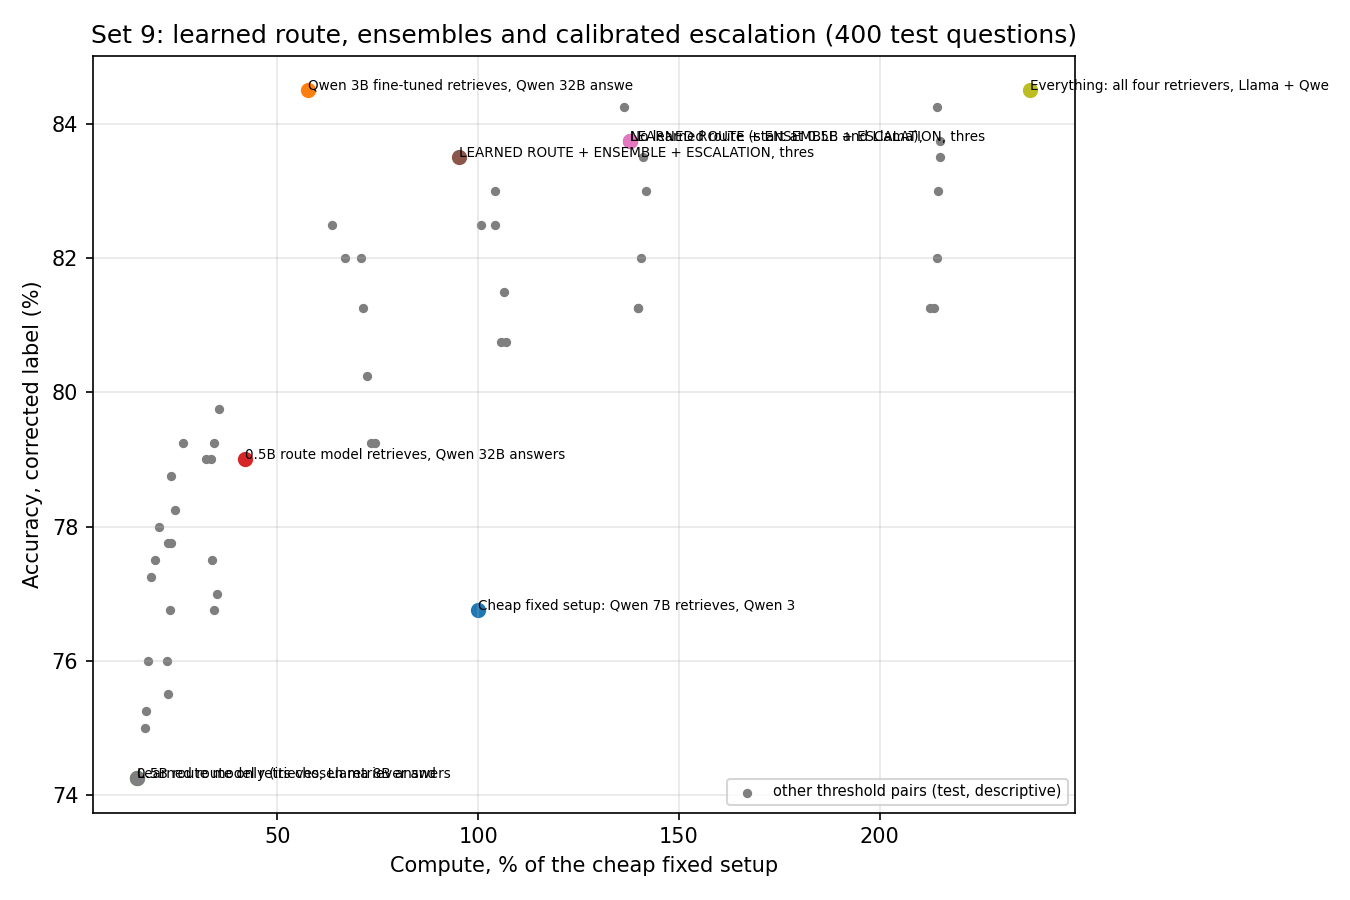

Excel workbook (incl. the per-question table with Sure/Unsure): /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_3__self-learnt-retrieval/20261013-162007_A100_route05/results/set9_learned_route.xlsx
Wall-clock this session (s): {'build_label': 212, 'merge': 302, 'install_vllm': 326, 'retrieve': 1367, 'reach': 3, 'copy_l8': 196, 'copy_q32': 301, 'answer_labels': 957, 'route_data': 1, 'train_route': 1448, 'route': 1832, 'answer': 682, 'answer_ref': 3, 'sample': 824, 'analyze': 97, 'total_session': 8064}

ALL DONE.
Saved to Drive.


In [23]:
if ALL_DONE:
    from IPython.display import Image, Markdown, display
    run_stage(["analyze", "--target", TARGET] + COMMON, "analyze.log")
    display(Markdown(open(f"{RUN_DIR}/results/summary.md").read()))
    display(Image(f"{RUN_DIR}/results/charts/accuracy_vs_compute.png"))
    print("Excel workbook (incl. the per-question table with Sure/Unsure):", f"{RUN_DIR}/results/set9_learned_route.xlsx")
TIMES["total_session"] = round(time.time() - T_START)
json.dump({"session": SESSION, "run_dir": RUN_DIR, "gpu": gpu, "seconds": TIMES, "code": EXPECTED_CODE, "complete": ALL_DONE},
          open(f"{SESSION_DIR}/session.json", "w"), indent=1)
print("Wall-clock this session (s):", TIMES)
print("\nALL DONE." if ALL_DONE else "\nNOT COMPLETE YET - run this notebook again to continue.")
try:
    drive.flush_and_unmount()
    print("Saved to Drive.")
except Exception as e:
    print("Drive flush skipped:", e)